In [ ]:
import torch
import torch.nn as nn

In [ ]:
torch.manual_seed(42)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = torch.Generator().manual_seed(42)

def generate_rings(n):
    points = []
    labels = []

    for label, radius in enumerate([1.0, 2.5, 4.0]):
        theta = torch.rand(n, generator=rng) * 2 * torch.pi
        r = radius + torch.randn(n, generator=rng) * 0.65

        x = r * torch.cos(theta)
        y = r * torch.sin(theta)

        ring = torch.stack((x, y), dim=1)

        points.append(ring)
        labels.extend([label] * n)

    X = torch.cat(points, dim=0)
    y = torch.tensor(labels, dtype=torch.long)

    indices = torch.randperm(len(X), generator=rng)

    return X[indices], y[indices]



X, y = generate_rings(1000)


In [ ]:
# ARCHITECTURE, 3 HIDDEN LAYERS
model = nn.Sequential(
    nn.Linear(2,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,3)
)

criterion = nn.CrossEntropyLoss()
output = model(X)
loss = criterion(output,y)
print(loss.item())

1.1147409677505493


In [ ]:
optimiser = torch.optim.SGD(model.parameters(), lr = 0.01)
for epoch in range(3000):
    output = model(X)
    loss = criterion(output,y)

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()
    
    if epoch%10 == 0:
        print(f"Epoch: {epoch}, Loss: {loss}")

Epoch: 0, Loss: 1.1147409677505493
Epoch: 10, Loss: 1.1125894784927368
Epoch: 20, Loss: 1.1106786727905273
Epoch: 30, Loss: 1.1089800596237183
Epoch: 40, Loss: 1.1074609756469727
Epoch: 50, Loss: 1.1060789823532104
Epoch: 60, Loss: 1.104819893836975
Epoch: 70, Loss: 1.1036632061004639
Epoch: 80, Loss: 1.1025937795639038
Epoch: 90, Loss: 1.1016064882278442
Epoch: 100, Loss: 1.1006985902786255
Epoch: 110, Loss: 1.099857211112976
Epoch: 120, Loss: 1.099074125289917
Epoch: 130, Loss: 1.0983413457870483
Epoch: 140, Loss: 1.0976566076278687
Epoch: 150, Loss: 1.0970174074172974
Epoch: 160, Loss: 1.0964125394821167
Epoch: 170, Loss: 1.0958352088928223
Epoch: 180, Loss: 1.0952929258346558
Epoch: 190, Loss: 1.094782829284668
Epoch: 200, Loss: 1.0943052768707275
Epoch: 210, Loss: 1.093859314918518
Epoch: 220, Loss: 1.0934360027313232
Epoch: 230, Loss: 1.0930330753326416
Epoch: 240, Loss: 1.0926439762115479
Epoch: 250, Loss: 1.09226655960083
Epoch: 260, Loss: 1.0918974876403809
Epoch: 270, Loss: 1

In [ ]:
model.eval()
with torch.no_grad():
    output = model(X)
    prediction = torch.argmax(output,dim = 1)
    b = (prediction == y)
    accuracy = b.float().mean() * 100
print(f"Accuracy: {accuracy} %")

Accuracy: 83.60000610351562 %


In [ ]:
X_test, y_test = generate_rings(300)

print("Training:", X.shape, y.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: torch.Size([3000, 2]) torch.Size([3000])
Testing: torch.Size([900, 2]) torch.Size([900])


In [ ]:
model.eval()
with torch.no_grad():
    output = model(X_test)
    prediction = torch.argmax(output,dim = 1)
    b = (prediction == y_test)
    accuracy = b.float().mean() * 100

print(f"Accuracy: {accuracy} %")

Accuracy: 85.22222137451172 %


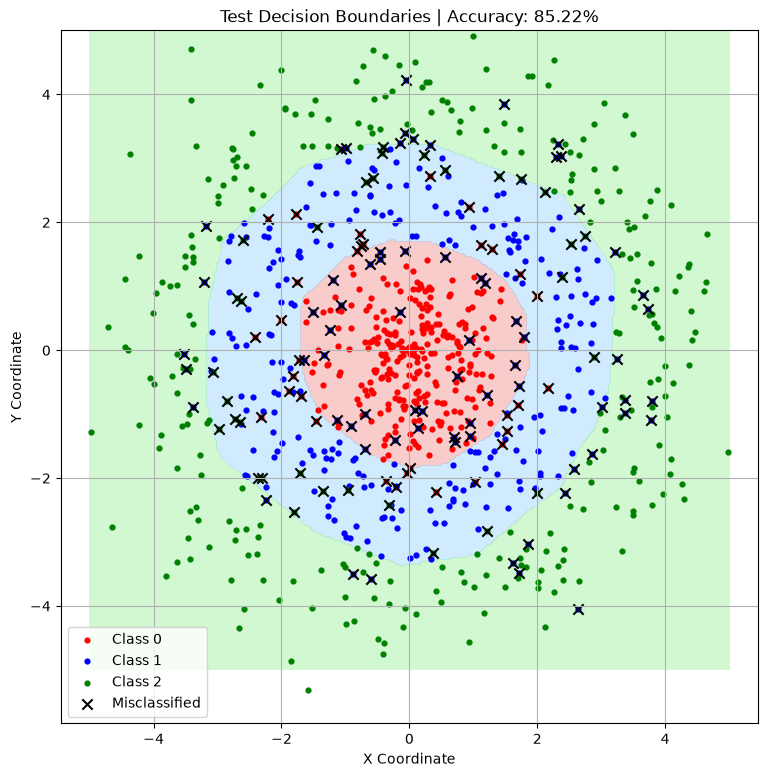

Test Accuracy: 85.22%
Misclassified Points: 133/900


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x_values = np.linspace(-5, 5, 300)
y_values = np.linspace(-5, 5, 300)

xx, yy = np.meshgrid(x_values, y_values)

grid_points = np.column_stack((xx.ravel(), yy.ravel()))
grid_tensor = torch.tensor(grid_points, dtype=torch.float32)


model.eval()

with torch.no_grad():
    grid_predictions = torch.argmax(model(grid_tensor), dim=1)
    test_predictions = torch.argmax(model(X_test), dim=1)


pred = grid_predictions.reshape(xx.shape).numpy()


incorrect = (test_predictions != y_test)


accuracy = (test_predictions == y_test).float().mean() * 100


plt.figure(figsize=(9, 9))

plt.contourf(
    xx, yy, pred,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=['lightcoral', 'lightskyblue', 'lightgreen'],
    alpha=0.4
)

colors = ['red', 'blue', 'green']

for i in range(3):
    plt.scatter(
        X_test[y_test == i, 0],
        X_test[y_test == i, 1],
        color=colors[i],
        s=12,
        label=f'Class {i}'
    )

plt.scatter(
    X_test[incorrect, 0],
    X_test[incorrect, 1],
    marker='x',
    color='black',
    s=55,
    linewidths=1.5,
    label='Misclassified'
)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title(f"Test Decision Boundaries | Accuracy: {accuracy.item():.2f}%")

plt.axis('equal')
plt.legend()
plt.grid(True)
plt.show()

print(f"Test Accuracy: {accuracy.item():.2f}%")
print(f"Misclassified Points: {incorrect.sum().item()}/900")